# Assignment 4: Energy Model Training from 10 to 20 Epochs

Continue training from the preserved epoch-10 checkpoint for 10 additional epochs. The architecture, data split, and training settings remain unchanged from the main notebook. Compare the results to assess whether additional training improves generated image quality.

## 1. Prepare the experiment

Load the data and define the same energy model, Langevin sampler, and training procedure used in the main notebook.

In [1]:
import copy
import json
import math
import random
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

In [2]:
SEED = 42
BATCH_SIZE = 128
IMAGE_SIZE = 32
NUM_CHANNELS = 3
EPOCHS = 20
LEARNING_RATE = 0.0001
SAMPLE_STEPS = 60
RESUME_PATH = Path("C:/Users/Milan_Chen/Desktop/SEM3/genai 5560/ASS4/outputs/energy_20261118_133522_361167/checkpoints/energy_epoch_010_baseline.pth")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

import sys

PROJECT_DIR = None
for folder in (Path.cwd(), *Path.cwd().parents):
    for candidate in (folder, folder / "APAN_5560genai_ass1"):
        if (candidate / "app" / "main.py").is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Cannot find the APAN_5560genai_ass1 project near this notebook.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / "data"
RUN_DIR = Path("C:/Users/Milan_Chen/Desktop/SEM3/genai 5560/ASS4/outputs/energy_continue_to_20_20261118_172742")
MODEL_DIR = RUN_DIR / "models"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"
for directory in (MODEL_DIR, CHECKPOINT_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Run directory:", RUN_DIR)

Device: cuda
Run directory: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\energy_continue_to_20_20261118_172742


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset, [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=transform
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Test:", len(test_dataset))

Train: 45000 Validation: 5000 Test: 10000


Image batch: torch.Size([128, 3, 32, 32])


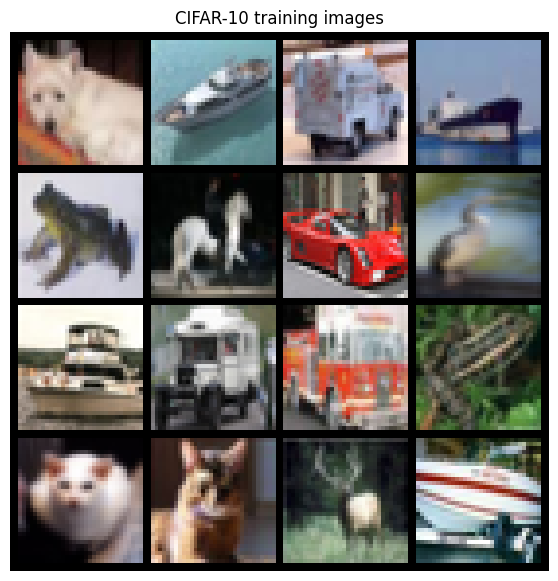

In [4]:
def show_images(images, title, nrow=4):
    grid = make_grid(images.detach().cpu(), nrow=nrow)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
show_images(((images[:16] + 1) / 2).clamp(0, 1), "CIFAR-10 training images")

In [5]:
def swish(x):
    return x * torch.sigmoid(x)


class EnergyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 2 * 2, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = swish(self.conv1(x))
        x = swish(self.conv2(x))
        x = swish(self.conv3(x))
        x = swish(self.conv4(x))
        x = self.flatten(x)
        x = swish(self.fc1(x))
        return self.fc2(x)

In [6]:
def generate_samples(nn_energy_model, inp_imgs, steps, step_size, noise_std):
    if steps < 1:
        raise ValueError("steps must be positive.")
    was_training = nn_energy_model.training
    nn_energy_model.eval()
    inp_imgs = inp_imgs.detach()
    try:
        for _ in range(steps):
            with torch.no_grad():
                noise = torch.randn_like(inp_imgs) * noise_std
                inp_imgs = (inp_imgs + noise).clamp(-1.0, 1.0)
            with torch.enable_grad():
                inp_imgs.requires_grad_(True)
                energy = nn_energy_model(inp_imgs)
                grads, = torch.autograd.grad(
                    energy, inp_imgs, grad_outputs=torch.ones_like(energy)
                )
            with torch.no_grad():
                grads = grads.clamp(-0.03, 0.03)
                inp_imgs = (inp_imgs - step_size * grads).clamp(-1.0, 1.0)
    finally:
        nn_energy_model.train(was_training)
    return inp_imgs.detach()

In [7]:
class Buffer:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.examples = [
            torch.rand((1, 3, 32, 32), device=device) * 2 - 1
            for _ in range(128)
        ]

    def sample_new_exmps(self, batch_size, steps, step_size, noise):
        n_new = np.random.binomial(batch_size, 0.05)
        new_rand_imgs = torch.rand((n_new, 3, 32, 32), device=self.device) * 2 - 1
        old_examples = random.choices(self.examples, k=batch_size - n_new)
        if old_examples:
            old_imgs = torch.cat(old_examples, dim=0)
            inp_imgs = torch.cat([new_rand_imgs, old_imgs], dim=0)
        else:
            inp_imgs = new_rand_imgs
        new_imgs = generate_samples(self.model, inp_imgs, steps, step_size, noise)
        self.examples = [img.clone() for img in new_imgs.split(1)] + self.examples
        self.examples = self.examples[:8192]
        return new_imgs

In [8]:
class Metric:
    def __init__(self):
        self.reset()

    def update(self, val, count=1):
        self.total += val.item() * count
        self.count += count

    def result(self):
        return self.total / self.count if self.count > 0 else 0.0

    def reset(self):
        self.total = 0.0
        self.count = 0


class EBM(nn.Module):
    def __init__(self, model, alpha, steps, step_size, noise, device):
        super().__init__()
        self.device = device
        self.model = model.to(device)
        self.buffer = Buffer(self.model, device)
        self.alpha = alpha
        self.steps = steps
        self.step_size = step_size
        self.noise = noise
        self.loss_metric = Metric()
        self.reg_loss_metric = Metric()
        self.cdiv_loss_metric = Metric()
        self.real_out_metric = Metric()
        self.fake_out_metric = Metric()

    def metrics(self):
        return {
            "loss": self.loss_metric.result(),
            "reg": self.reg_loss_metric.result(),
            "cdiv": self.cdiv_loss_metric.result(),
            "real": self.real_out_metric.result(),
            "fake": self.fake_out_metric.result(),
        }

    def reset_metrics(self):
        for metric in (self.loss_metric, self.reg_loss_metric, self.cdiv_loss_metric,
                       self.real_out_metric, self.fake_out_metric):
            metric.reset()

    def train_step(self, real_imgs, optimizer):
        self.model.train()
        real_imgs = real_imgs.to(self.device)
        real_imgs = (real_imgs + torch.randn_like(real_imgs) * self.noise).clamp(-1, 1)
        batch_size = real_imgs.size(0)
        fake_imgs = self.buffer.sample_new_exmps(
            batch_size, self.steps, self.step_size, self.noise
        )
        inp_imgs = torch.cat([real_imgs, fake_imgs], dim=0).detach()
        out_scores = self.model(inp_imgs)
        real_out, fake_out = torch.split(out_scores, [batch_size, batch_size], dim=0)
        cdiv_loss = real_out.mean() - fake_out.mean()
        reg_loss = self.alpha * (real_out.square().mean() + fake_out.square().mean())
        loss = cdiv_loss + reg_loss
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=0.1)
        optimizer.step()
        self.loss_metric.update(loss, batch_size)
        self.reg_loss_metric.update(reg_loss, batch_size)
        self.cdiv_loss_metric.update(cdiv_loss, batch_size)
        self.real_out_metric.update(real_out.mean(), batch_size)
        self.fake_out_metric.update(fake_out.mean(), batch_size)
        return self.metrics()

    def test_step(self, real_imgs):
        self.model.eval()
        real_imgs = real_imgs.to(self.device)
        batch_size = real_imgs.size(0)
        fake_imgs = torch.rand_like(real_imgs) * 2 - 1
        with torch.no_grad():
            out_scores = self.model(torch.cat([real_imgs, fake_imgs], dim=0))
            real_out, fake_out = out_scores.split(batch_size)
            cdiv = real_out.mean() - fake_out.mean()
        self.cdiv_loss_metric.update(cdiv, batch_size)
        self.real_out_metric.update(real_out.mean(), batch_size)
        self.fake_out_metric.update(fake_out.mean(), batch_size)
        return {
            "cdiv": self.cdiv_loss_metric.result(),
            "real": self.real_out_metric.result(),
            "fake": self.fake_out_metric.result(),
        }

## 2. Restore the epoch-10 checkpoint

Restore the model weights, optimizer state, replay buffer, sampling settings, fixed initial samples, and training history. Continue from epoch 11 and save new results to a separate run directory.

In [9]:
energy_model = EnergyModel().to(device)
ebm = EBM(energy_model, alpha=0.1, steps=60, step_size=10.0, noise=0.005, device=device)
optimizer = optim.Adam(energy_model.parameters(), lr=LEARNING_RATE)
fixed_noise = torch.rand(16, 3, 32, 32, device=device) * 2 - 1
start_epoch = 0
history = []

if RESUME_PATH is not None:
    checkpoint = torch.load(RESUME_PATH, map_location=device, weights_only=True)
    energy_model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    ebm.buffer.examples = list(checkpoint["buffer_examples"].to(device).split(1))
    for name in ("alpha", "steps", "step_size", "noise"):
        setattr(ebm, name, checkpoint[name])
    fixed_noise = checkpoint["fixed_noise"].to(device)
    start_epoch = checkpoint["epoch"]
    history = checkpoint["history"]

print("Energy output shape:", energy_model(images[:2].to(device)).shape)
print("Completed epochs:", start_epoch)

Energy output shape: torch.Size([2, 1])
Completed epochs: 10


## 3. Train and save progress

Each epoch saves a generated grid, history.json, and energy_latest.pth.
The checkpoint includes the replay buffer and optimizer for continuation.
The same initial images are reused for epoch grids, but Langevin noise is resampled.
Review sample grids as well as losses before deciding whether more training is needed.

In [10]:
def train_energy(ebm, train_loader, val_loader, optimizer, epochs,
                 checkpoint_dir, sample_dir, fixed_noise, sample_steps,
                 start_epoch=0, history=None):
    history = [] if history is None else history
    for epoch in range(start_epoch, epochs):
        ebm.reset_metrics()
        progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]")
        for images, _ in progress:
            metrics = ebm.train_step(images.to(ebm.device), optimizer)
            progress.set_postfix(loss=f"{metrics['loss']:.4f}")
        train_metrics = ebm.metrics().copy()
        ebm.reset_metrics()
        for images, _ in tqdm(val_loader, desc="Validation"):
            ebm.test_step(images.to(ebm.device))
        val_metrics = ebm.metrics().copy()
        record = {
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_real_energy": train_metrics["real"],
            "train_fake_energy": train_metrics["fake"],
            "val_real_energy": val_metrics["real"],
            "val_random_energy": val_metrics["fake"],
            "val_energy_gap": val_metrics["cdiv"],
        }
        history.append(record)
        samples = generate_samples(
            ebm.model, fixed_noise.clone(), sample_steps, ebm.step_size, ebm.noise
        )
        samples = ((samples + 1) / 2).clamp(0, 1)
        save_image(samples, sample_dir / f"epoch_{epoch + 1:03d}.png", nrow=4)
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": ebm.model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "buffer_examples": torch.cat(ebm.buffer.examples).cpu(),
            "fixed_noise": fixed_noise.cpu(),
            "history": history,
            "alpha": ebm.alpha,
            "steps": ebm.steps,
            "step_size": ebm.step_size,
            "noise": ebm.noise,
            "image_size": 32,
            "num_channels": 3,
        }
        torch.save(checkpoint, checkpoint_dir / "energy_latest.pth")
        (checkpoint_dir.parent / "history.json").write_text(json.dumps(history, indent=2))
        print(record)
        show_images(samples, f"Energy model: epoch {epoch + 1}")
    return history

Epoch 11/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

C:\Users\Milan_Chen\Documents\ChatGPT\anomaly detection\.venv-ass5-gpu\Lib\site-packages\torch\autograd\graph.py:979: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:408.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 11, 'train_loss': 0.00011643767926014132, 'train_real_energy': 7.969674819873439e-05, 'train_fake_energy': 1.6539308925469717e-05, 'val_real_energy': -0.004744716498628259, 'val_random_energy': 3.6965609031677245, 'val_energy_gap': -3.701305602264404}


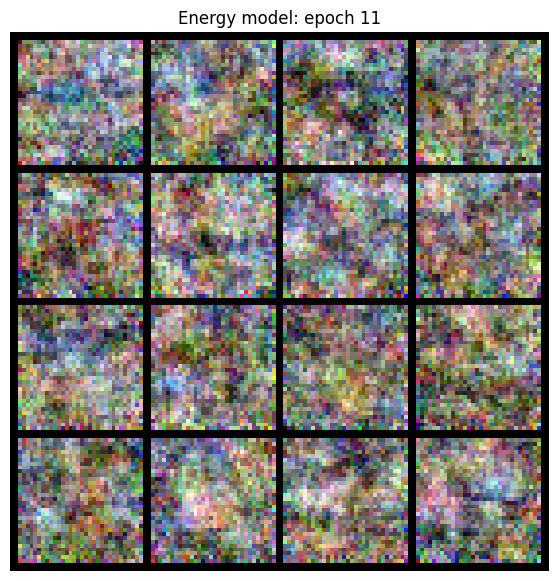

Epoch 12/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 12, 'train_loss': 0.0003541082963657876, 'train_real_energy': 0.0004806132077756855, 'train_fake_energy': 0.00018567370991739963, 'val_real_energy': -0.0012713857017457486, 'val_random_energy': 3.880012801361084, 'val_energy_gap': -3.881284208679199}


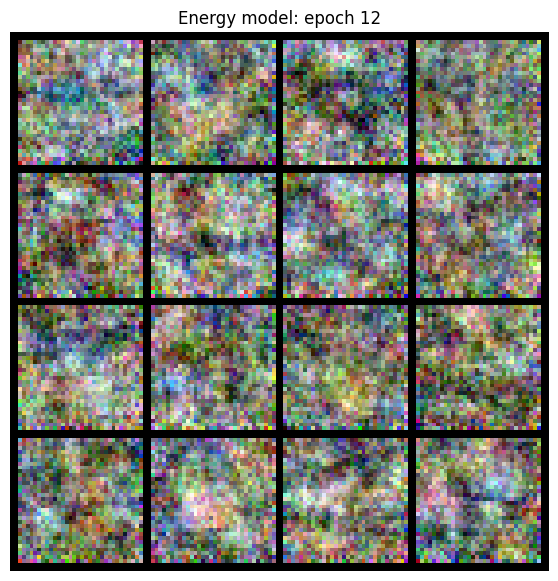

Epoch 13/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 13, 'train_loss': -2.6229377794596885e-05, 'train_real_energy': 0.0004227083867208825, 'train_fake_energy': 0.0004925110341360172, 'val_real_energy': -0.003911523976176977, 'val_random_energy': 4.551661940002441, 'val_energy_gap': -4.555573471069336}


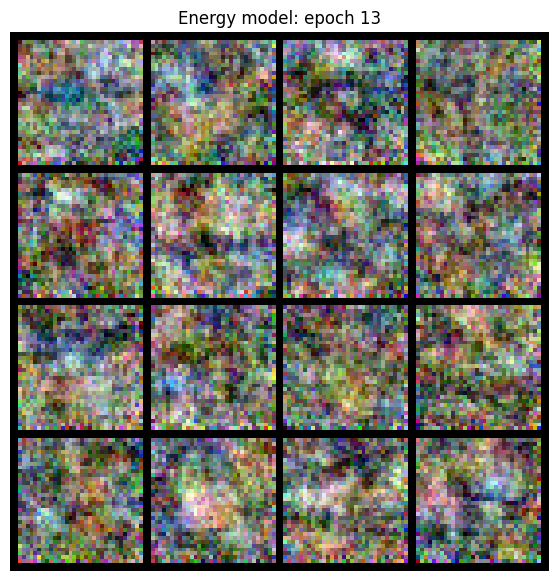

Epoch 14/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 14, 'train_loss': -9.11198258244743e-05, 'train_real_energy': 8.593668891893078e-05, 'train_fake_energy': 0.00023546238272554345, 'val_real_energy': 0.0020158237874507903, 'val_random_energy': 4.8127160789489745, 'val_energy_gap': -4.810700247955323}


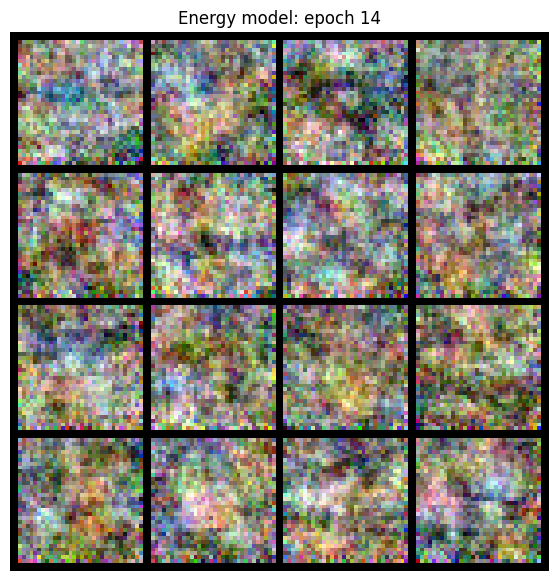

Epoch 15/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 15, 'train_loss': 0.00041238901680335405, 'train_real_energy': -8.093373456762897e-05, 'train_fake_energy': -0.0004277042194786999, 'val_real_energy': 0.0022485674075782298, 'val_random_energy': 4.687154019165039, 'val_energy_gap': -4.6849054458618165}


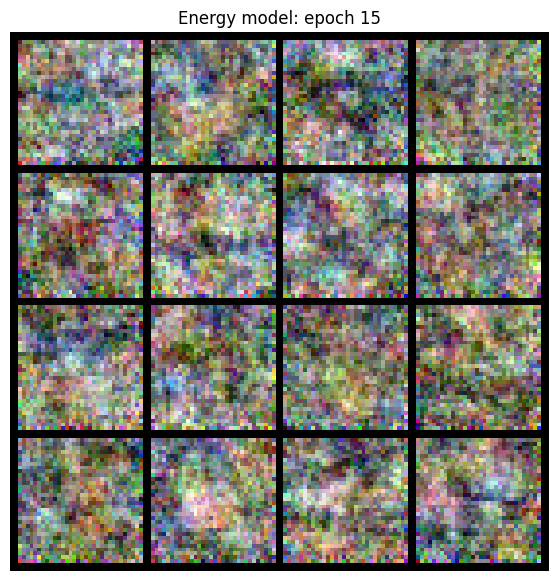

Epoch 16/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 16, 'train_loss': 5.509748896583915e-05, 'train_real_energy': 0.0004232999246670968, 'train_fake_energy': 0.0004163348151163922, 'val_real_energy': -0.0010206438753753901, 'val_random_energy': 5.103381577301025, 'val_energy_gap': -5.104402220153808}


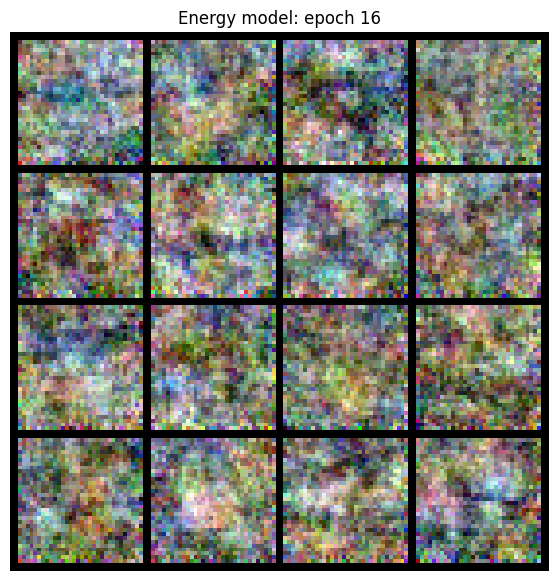

Epoch 17/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 17, 'train_loss': 6.126371446686486e-05, 'train_real_energy': -0.00012238131611504489, 'train_fake_energy': -0.00012009515708519353, 'val_real_energy': 0.004979368765652179, 'val_random_energy': 5.337764286804199, 'val_energy_gap': -5.332784941864014}


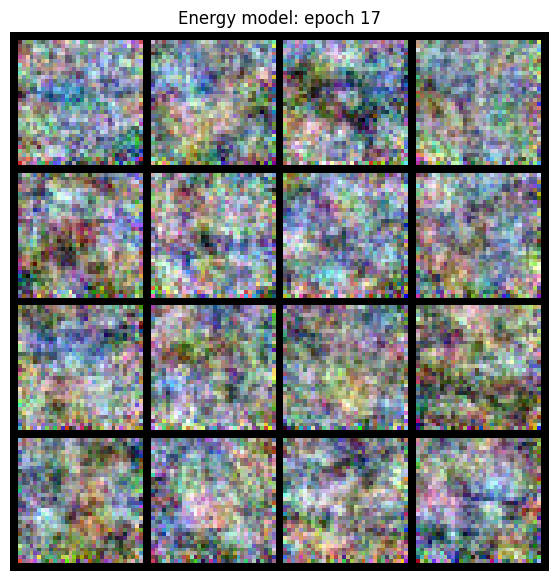

Epoch 18/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 18, 'train_loss': 0.00036231708648071313, 'train_real_energy': 0.00013519803049663704, 'train_fake_energy': -0.00016820596969789928, 'val_real_energy': -0.0036395656913518907, 'val_random_energy': 5.31626431274414, 'val_energy_gap': -5.3199038932800295}


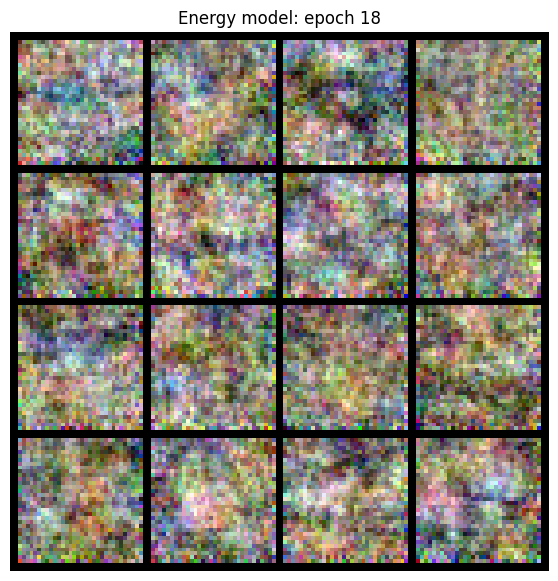

Epoch 19/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 19, 'train_loss': 5.7591620915465885e-05, 'train_real_energy': 0.0002473310974737008, 'train_fake_energy': 0.0002372959581307239, 'val_real_energy': -0.0009197321705520153, 'val_random_energy': 5.512764398193359, 'val_energy_gap': -5.513684095001221}


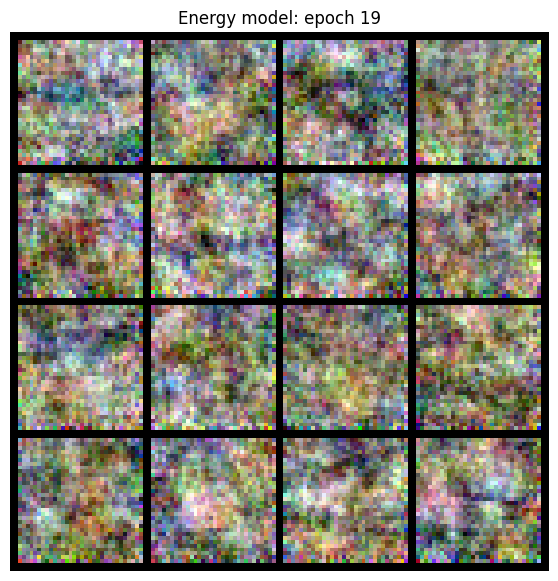

Epoch 20/20 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 20, 'train_loss': 6.048141762924691e-05, 'train_real_energy': 0.0004234564976973666, 'train_fake_energy': 0.000415802502590749, 'val_real_energy': -0.0021433915242552756, 'val_random_energy': 5.6977265953063965, 'val_energy_gap': -5.6998699691772465}


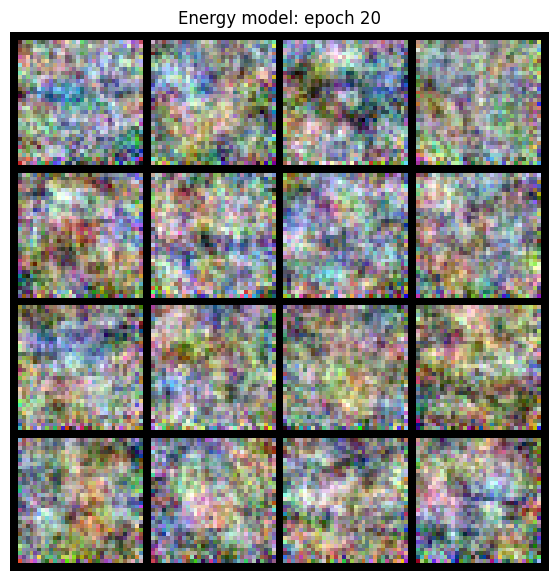

In [11]:
history = train_energy(
    ebm, train_loader, val_loader, optimizer, EPOCHS,
    CHECKPOINT_DIR, SAMPLE_DIR, fixed_noise, SAMPLE_STEPS,
    start_epoch=start_epoch, history=history
)

## 4. Inspect training and the held-out diagnostic

An energy gap describes the model's scores for the chosen image distributions.
It does not establish sample realism. Compare the saved images with real CIFAR-10 images.

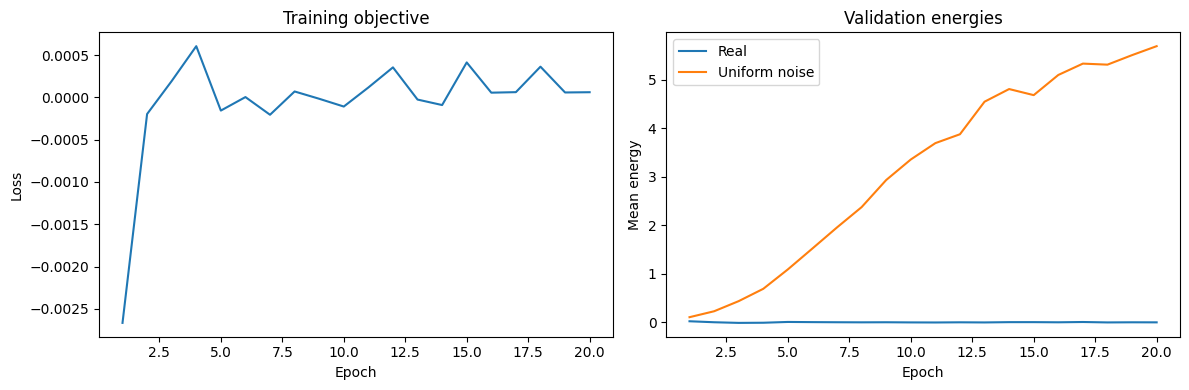

Test diagnostic:   0%|          | 0/79 [00:00<?, ?it/s]

{'cdiv': -5.699241054534912, 'real': -0.002160511760599911, 'fake': 5.697080551147461}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [row["epoch"] for row in history]
axes[0].plot(epochs, [row["train_loss"] for row in history])
axes[0].set(title="Training objective", xlabel="Epoch", ylabel="Loss")
axes[1].plot(epochs, [row["val_real_energy"] for row in history], label="Real")
axes[1].plot(epochs, [row["val_random_energy"] for row in history], label="Uniform noise")
axes[1].set(title="Validation energies", xlabel="Epoch", ylabel="Mean energy")
axes[1].legend()
plt.tight_layout()
plt.show()

ebm.reset_metrics()
for images, _ in tqdm(test_loader, desc="Test diagnostic"):
    test_metrics = ebm.test_step(images.to(device))
print(test_metrics)

## 5. Compare epochs 10 and 20

Continuing training from 10 to 20 epochs did not produce a clear visual improvement in the inspected samples. Colored textures and grid-like patterns remained, and recognizable objects were still absent. Although the real-versus-random energy gap increased in magnitude, this did not translate into visibly more realistic samples under the tested settings.

## 6. Compare sampling steps

Use the trained energy model to compare 60, 200, and 500 Langevin steps.
All settings share the same initial images and random seed, so the shorter sampling runs follow the same initial trajectory as the longer runs. Model weights remain unchanged.
Compare object structure, noise, and repeated patterns. Lower energy alone does not establish better image quality.

Steps: 60, mean energy: 0.027792
Steps: 200, mean energy: -0.002598
Steps: 500, mean energy: -0.014966


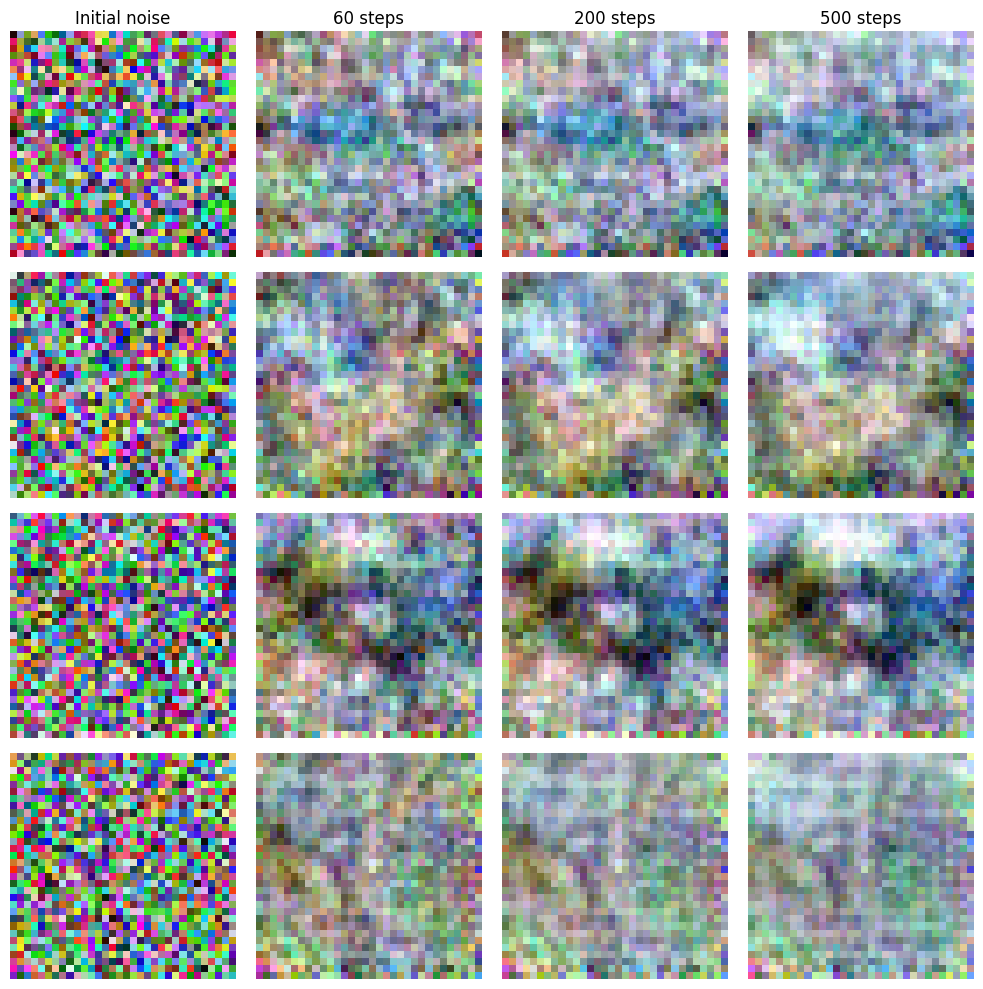

Saved: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\energy_continue_to_20_20261118_172742\samples\sampling_steps_comparison.png


In [13]:
energy_model.eval()

initial_images = fixed_noise[:4].detach().clone().to(device)
step_counts = [60, 200, 500]
results = {}
cuda_devices = [torch.cuda.current_device()] if device.type == "cuda" else []

for steps in step_counts:
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(123)
        samples = generate_samples(
            energy_model,
            initial_images.clone(),
            steps=steps,
            step_size=ebm.step_size,
            noise_std=ebm.noise,
        )

    results[steps] = samples.detach().cpu()

    with torch.no_grad():
        mean_energy = energy_model(samples).mean().item()

    print(f"Steps: {steps}, mean energy: {mean_energy:.6f}")

columns = [initial_images.cpu()] + [results[s] for s in step_counts]
titles = ["Initial noise"] + [f"{s} steps" for s in step_counts]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for col, (batch, title) in enumerate(zip(columns, titles)):
    display_images = ((batch + 1) / 2).clamp(0, 1)

    for row in range(4):
        axes[row, col].imshow(display_images[row].permute(1, 2, 0))
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(title)

plt.tight_layout()
comparison_path = SAMPLE_DIR / "sampling_steps_comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", comparison_path)

## 7. Export and verify the API checkpoint

Export the final trained network to models/cifar10_energy.pth. The API uses
the matching EnergyModel and generate_samples definitions in helper_lib/energy.py.
Reload on CPU and compare its energy scores with the GPU-trained model before generating fresh samples.
This export is saved in this continuation run's models folder. The existing API weights are preserved.

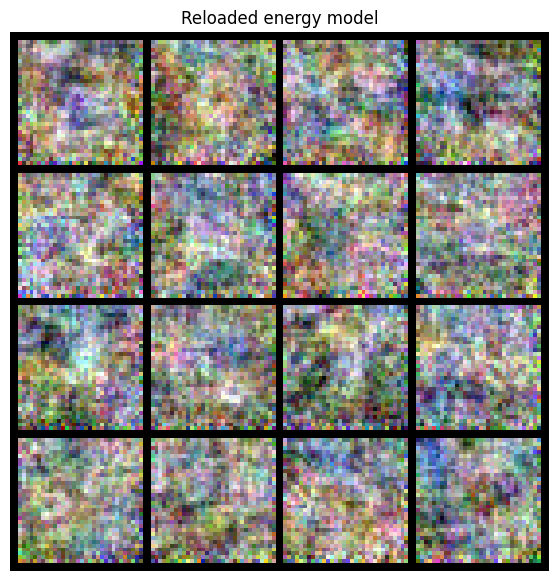

Exported: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\energy_continue_to_20_20261118_172742\models\cifar10_energy.pth


In [14]:
checkpoint = torch.load(CHECKPOINT_DIR / "energy_latest.pth", map_location="cpu", weights_only=True)
export = {name: checkpoint[name] for name in (
    "model_state_dict", "epoch", "image_size", "num_channels", "step_size", "noise"
)}
export_path = MODEL_DIR / "cifar10_energy.pth"
torch.save(export, export_path)

from helper_lib.energy import EnergyModel as APIEnergyModel
from helper_lib.energy import generate_samples as api_generate_samples

reloaded_model = APIEnergyModel()
reloaded_model.load_state_dict(torch.load(export_path, weights_only=True)["model_state_dict"])
reloaded_model.eval()
energy_model.eval()
probe = fixed_noise[:2]
with torch.no_grad():
    expected = energy_model(probe).cpu()
    actual = reloaded_model(probe.cpu())
torch.testing.assert_close(actual, expected, rtol=1e-4, atol=1e-5)
samples = api_generate_samples(
    reloaded_model, torch.rand(16, 3, 32, 32) * 2 - 1,
    SAMPLE_STEPS, export["step_size"], export["noise"]
)
samples = ((samples + 1) / 2).clamp(0, 1)
save_image(samples, SAMPLE_DIR / "final_samples.png", nrow=4)
show_images(samples, "Reloaded energy model")
print("Exported:", export_path)

## 8. Keep the baseline API weights

This continuation saves its export in RUN_DIR/models/cifar10_energy.pth. The API still uses the original 10-epoch export. Compare both experiments before selecting a model for deployment.